# Книжный рекомендательный сервис

Из условия домашнего задания:

**Цель:** реализовать, проанализировать и сравнить различные подходы рекомендательных систем для сервиса по подбору книг.

**Основные этапы:**

1. Подготовка данных и анализ - исследовать датасет Goodbooks-10k, выявить особенности и проблемы.
2. Реализация моделей - последовательно построить бейзлайны: популярные книги, контентная модель (например, с использованием TF-IDF для векторизации описаний книг), Item-based CF и SVD.
3. Сравнение и выводы - оценить качество моделей с помощью метрик, сравнить результаты и предложить идеи для улучшения.

Качество проверим по RMSE, Precision@K, Recall@K и nDCG@K.
Запись @K означает, что смотрим только первые K рекомендаций.

## Импорты

In [1]:
import os
import gc
import json
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits
from IPython.display import display

# Кэш библиотеки храним рядом с ноутбуком
os.environ.setdefault("SURPRISE_DATA_FOLDER", str(Path(".cache/surprise").resolve()))
from surprise import Dataset, Reader, SVD, accuracy

In [2]:
# Настройки
DATA, RESULTS = Path("data"), Path("results")
DATA.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
SEED, K, BATCH = 42, 10, 256
threads = threadpool_limits(limits=4)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": 0.15})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()

## Загрузка данных

Загрузим оценки, книги и теги. Проверим размеры файлов, чтобы дальше понимать, с какими данными работаем.

In [3]:
for name in ["ratings", "books", "tags", "book_tags"]:
    file = DATA / f"{name}.csv"
    if not file.exists():
        urlretrieve(f"https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/{name}.csv", file)

ratings = pd.read_csv(DATA / "ratings.csv")
books = pd.read_csv(DATA / "books.csv").sort_values("book_id").reset_index(drop=True)
tags = pd.read_csv(DATA / "tags.csv")
book_tags = pd.read_csv(DATA / "book_tags.csv")

print('ratings:', ratings.shape)
print('books:', books.shape)
print('tags:', tags.shape)
print('book_tags:', book_tags.shape)

ratings: (5976479, 3)
books: (10000, 23)
tags: (34252, 2)
book_tags: (999912, 3)


## 1. Анализ данных

Посмотрим на пропуски, оценки, активность читателей и популярность книг.
Проверим, какие проблемы нужно учесть при обучении моделей.

In [4]:
for name, df in [('ratings', ratings), ('books', books), ('tags', tags), ('book_tags', book_tags)]:
    print(name)
    print('Пропуски:', df.isna().sum().sum())
    print('Дубли строк:', df.duplicated().sum())

assert not ratings.duplicated(['user_id', 'book_id']).any()
assert ratings.notna().all().all() and ratings.rating.between(1, 5).all()
assert books.goodreads_book_id.is_unique and tags.tag_id.is_unique

user_activity = ratings.groupby('user_id').size()
book_activity = ratings.groupby('book_id').size()
density = len(ratings) / (len(user_activity) * len(books))
top_share = book_activity.nlargest(1000).sum() / len(ratings)

print('Средняя оценка:', round(ratings.rating.mean(), 2))
print('Доля оценок 4-5:', round((ratings.rating >= 4).mean(), 4))
print('Заполненность матрицы:', round(density, 4))
print('Доля оценок у 10% самых популярных книг:', round(top_share, 4))

ratings
Пропуски: 0


Дубли строк: 0
books
Пропуски: 2975
Дубли строк: 0
tags
Пропуски: 0
Дубли строк: 0
book_tags
Пропуски: 0
Дубли строк: 6


Средняя оценка: 3.92
Доля оценок 4-5: 0.6897
Заполненность матрицы: 0.0112
Доля оценок у 10% самых популярных книг: 0.532


In [5]:
print('Оценок у читателя:')
print(user_activity.describe())
print('Оценок у книги:')
print(book_activity.describe())

print('Самые активные читатели:', user_activity.nlargest(3))
print('Читатели с малой историей:', user_activity.nsmallest(3))
print('Популярные книги:', book_activity.nlargest(3))
print('Книги с малым числом оценок:', book_activity.nsmallest(3))

Оценок у читателя:
count    53424.000000
mean       111.868804
std         26.071224
min         19.000000
25%         96.000000
50%        111.000000
75%        128.000000
max        200.000000
dtype: float64
Оценок у книги:
count    10000.000000
mean       597.647900
std       1267.289788
min          8.000000
25%        155.000000
50%        248.000000
75%        503.000000
max      22806.000000
dtype: float64
Самые активные читатели: user_id
12874    200
30944    200
12381    199
dtype: int64
Читатели с малой историей: user_id
34590    19
43675    20
32128    21
dtype: int64
Популярные книги: book_id
1    22806
2    21850
4    19088
dtype: int64
Книги с малым числом оценок: book_id
7803     8
9345    11
9486    24
dtype: int64


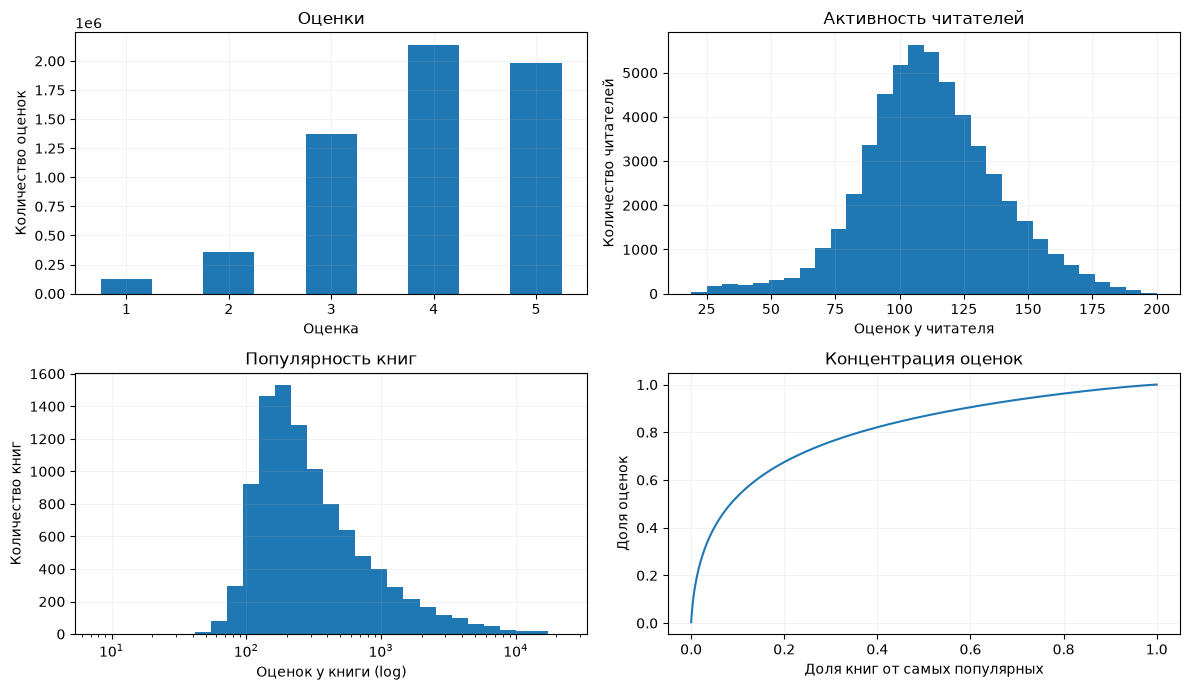

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0, 0], rot=0)
ax[0, 0].set(title="Оценки", xlabel="Оценка", ylabel="Количество оценок")
ax[0, 1].hist(user_activity, bins=30)
ax[0, 1].set(title="Активность читателей", xlabel="Оценок у читателя", ylabel="Количество читателей")
ax[1, 0].hist(book_activity, bins=np.geomspace(book_activity.min(), book_activity.max(), 30))
ax[1, 0].set(xscale="log", title="Популярность книг", xlabel="Оценок у книги (log)", ylabel="Количество книг")
ax[1, 1].plot(np.arange(1, len(books) + 1) / len(books), book_activity.sort_values(ascending=False).cumsum() / len(ratings))
ax[1, 1].set(title="Концентрация оценок", xlabel="Доля книг от самых популярных", ylabel="Доля оценок")
plot_save("eda_ratings_users_books")

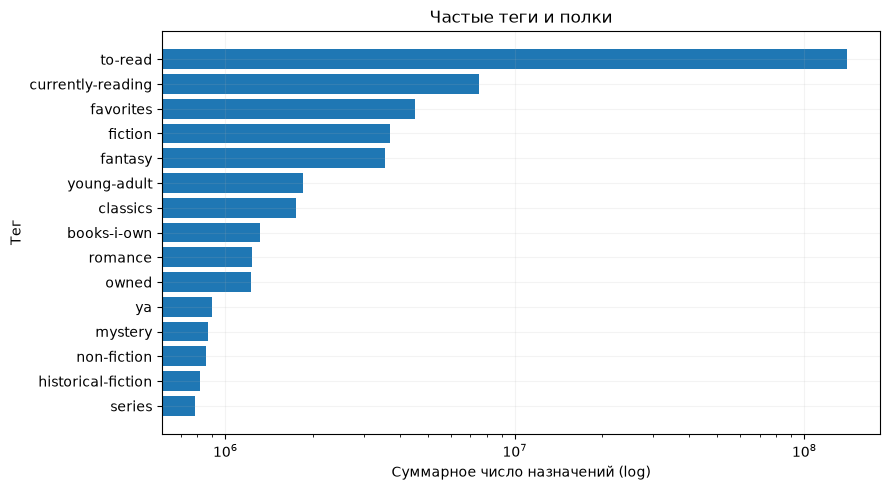

In [7]:
tag_counts = book_tags.groupby("tag_id")["count"].sum().nlargest(15).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(tags.set_index("tag_id").loc[tag_counts.index, "tag_name"], tag_counts)
plt.xscale("log")
plt.title("Частые теги и полки")
plt.xlabel("Суммарное число назначений (log)")
plt.ylabel("Тег")
plot_save("eda_tags")

Почти 69% оценок - это 4 и 5, средняя 3,92. Матрица заполнена на 1,12%:
отсутствие оценки не будем считать неприязнью к книге.

У читателя 19-200 оценок, медиана 111. Читателей без истории нет, настоящий холодный старт не проверим.
10% книг собрали 53,2% оценок. Сам каталог состоит из популярных книг, поэтому выводы о длинном хвосте ограничены.

У 585 книг нет `original_title`, возьмём `title`. В `book_tags` 6 повторных строк из почти миллиона.
`to-read` означает желание прочитать, а не жанр. Общие полки уберём из описаний.

## 2. Разбиение

Разделим оценки на train/validation/test (80/10/10), сохранив каждого читателя в обучении.
На validation выберем SVD, затем обучим её на 90% оценок.
Test оставим для честного сравнения моделей.

In [8]:
train, holdout = train_test_split(ratings, test_size=0.2, stratify=ratings.user_id, random_state=SEED)
validation, test = train_test_split(holdout, test_size=0.5, stratify=holdout.user_id, random_state=SEED)

# Проверяем, что оценки не пересекаются
assert train.index.intersection(test.index).empty and validation.index.intersection(test.index).empty
assert train.index.intersection(validation.index).empty

train_final = pd.concat([train, validation], ignore_index=True)
U, I = len(user_activity), len(books)
assert np.array_equal(np.sort(ratings.user_id.unique()), np.arange(1, U + 1))
assert np.array_equal(books.book_id, np.arange(1, I + 1))
assert test.user_id.isin(train_final.user_id).all() and test.book_id.isin(train_final.book_id).all()

print(f"Train: {len(train):,}; validation: {len(validation):,}; test: {len(test):,}")

Train: 4,781,183; validation: 597,648; test: 597,648


In [9]:
# Строки матриц - читатели, столбцы - книги
def matrix(frame, values):
    return sparse.csr_matrix((np.asarray(values, dtype="float32"),
                              (frame.user_id.to_numpy() - 1, frame.book_id.to_numpy() - 1)), shape=(U, I))

R = matrix(train_final, train_final.rating)
seen = matrix(train_final, np.ones(len(train_final)))
positive = matrix(train_final, train_final.rating >= 4)
relevant = matrix(test, test.rating >= 4)
positive.eliminate_zeros()
relevant.eliminate_zeros()
n_relevant = np.asarray(relevant.sum(axis=1)).ravel().astype(int)

В тесте 597 648 оценок, пересечений с обучением нет.
Кандидаты - весь каталог без уже оценённых книг. Агрегаты оценок из `books` не используем.
Дат нет, теги доступны только общим снимком.

## 3. Popularity

Начнём с книг с высоким средним рейтингом и хотя бы 50 обучающими оценками.
Проверим, насколько такой простой вариант уступает персональным рекомендациям.

In [10]:
# Рейтинг и число оценок считаем только на обучении
book_stats = train_final.groupby("book_id").rating.agg(["mean", "count"]).reindex(books.book_id)
global_mean = train_final.rating.mean()
popularity = book_stats["mean"].fillna(global_mean).to_numpy(dtype="float32")
eligible = book_stats["count"].to_numpy() >= 50

def top_indices(scores, n):
    candidates = np.argpartition(-scores, n - 1, axis=-1)[..., :n]
    order = np.argsort(-np.take_along_axis(scores, candidates, axis=-1), axis=-1, kind="stable")
    return np.take_along_axis(candidates, order, axis=-1)

def book_table(indices):
    return books.iloc[indices][["book_id", "title", "authors"]].reset_index(drop=True)

display(book_table(top_indices(np.where(eligible, popularity, -np.inf), 5)))

,book_id,title,authors
0,3628,The Complete Calvin and Hobbes,Bill Watterson
1,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
2,8978,The Revenge of the Baby-Sat,Bill Watterson
3,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
4,1788,The Calvin and Hobbes Tenth Anniversary Book,Bill Watterson


В топ попали несколько сборников Calvin and Hobbes. Вкусы читателя здесь не учитываются, список для всех один.

## 4. Content-Based

Найдём похожие книги по TF-IDF названия и 20 частых содержательных тегов.
Профиль читателя соберём по книгам с оценкой 4-5, чтобы учесть его интересы.

In [11]:
excluded = {"to-read", "currently-reading", "read", "favorites", "favourites", "owned", "books-i-own",
            "my-books", "library", "ebook", "ebooks", "kindle", "default"}
links = book_tags.merge(tags, on="tag_id", validate="many_to_one").merge(
    books[["book_id", "goodreads_book_id"]], on="goodreads_book_id", validate="many_to_one")
top_tags = links.loc[~links.tag_name.isin(excluded)].sort_values(
    ["book_id", "count", "tag_name"], ascending=[True, False, True]).groupby("book_id").head(20)
tag_text = top_tags.groupby("book_id").tag_name.agg(lambda x: " ".join(x.str.replace("-", "_", regex=False)))
text = books.original_title.fillna(books.title) + " " + books.book_id.map(tag_text).fillna("")

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=40000,
                           stop_words="english", strip_accents="unicode", dtype=np.float32)
X = vectorizer.fit_transform(text)
profiles = normalize(positive @ X)
no_profile = np.asarray(positive.sum(axis=1)).ravel() == 0

In [12]:
def get_similar_books(book_id, N=5):
    if not 1 <= book_id <= I:
        raise ValueError("Неизвестная книга")
    scores = (X[book_id - 1] @ X.T).toarray().ravel()
    scores[book_id - 1] = -np.inf
    return book_table(top_indices(scores, min(N, I - 1)))

display(get_similar_books(258))

,book_id,title,authors
0,1467,The Angel's Game (The Cemetery of Forgotten Bo...,"Carlos Ruiz Zafón, Lucia Graves"
1,5822,"The Prince of Mist (Niebla, #1)","Carlos Ruiz Zafón, Lucia Graves"
2,5022,Marina,Carlos Ruiz Zafón
3,9223,La vida del Lazarillo de Tormes,Anonymous
4,2899,The Museum of Extraordinary Things,Alice Hoffman


Для «Тени ветра» первыми нашлись три другие книги Сафона. По тексту получается разумная близость,
но понравятся ли книги читателю, ещё нужно проверить.

## 5. Item-Based CF

Найдём похожие книги по оценкам и спрогнозируем оценку через соседей.
Сначала вычтем среднее читателя, чтобы учесть разницу в привычках оценивания.
Оставим 100 положительных соседей и минимум 5 общих читателей.

In [13]:
user_mean = (np.asarray(R.sum(axis=1)).ravel() / np.diff(R.indptr)).astype("float32")
residuals = R.copy()
residuals.data -= np.repeat(user_mean, np.diff(R.indptr))
normalized = normalize(residuals.T.tocsr())

In [14]:
# Считаем сходство блоками и сохраняем только соседей
row_parts, col_parts, value_parts = [], [], []
for start in range(0, I, BATCH):
    rows = np.arange(start, min(start + BATCH, I))
    common = (seen[:, rows].T @ seen).toarray()
    similarity = (normalized[rows] @ normalized.T).toarray()
    similarity *= common / (common + 25)
    similarity[(common < 5) | (similarity < 0)] = 0
    similarity[np.arange(len(rows)), rows] = 0
    neighbors = top_indices(similarity, 100)
    values = np.take_along_axis(similarity, neighbors, axis=1)
    keep = values > 0
    row_parts.append(np.broadcast_to(rows[:, None], neighbors.shape)[keep])
    col_parts.append(neighbors[keep])
    value_parts.append(values[keep])
S = sparse.csr_matrix((np.concatenate(value_parts), (np.concatenate(row_parts), np.concatenate(col_parts))), shape=(I, I))

In [15]:
def cf_scores(rows):
    numerator = (residuals[rows] @ S.T).toarray()
    denominator = (seen[rows] @ S.T).toarray()
    return user_mean[rows, None] + np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)

Чем меньше общих читателей у двух книг, тем сильнее уменьшаем их сходство.
Если оценённых соседей нет, прогноз - средняя оценка читателя.

Сравнивать все книги со всеми читателями дорого: если книг станет вдвое больше,
число попарных сравнений вырастет примерно в четыре раза. Полная матрица сходств тоже вырастет в четыре раза.
У разреженного расчёта работа зависит от числа пар книг, оценённых одним читателем.

Поэтому считаем сходства блоками и храним только 100 соседей каждой книги.
Память для блока растёт с его размером и числом книг, а память для соседей - с числом книг и соседей.
Для большого каталога можно сначала отбирать кандидатов или использовать приближённый поиск соседей (ANN).

## 6. SVD

Обучим SVD из Surprise для предсказания оценок. Выберем из двух вариантов по validation RMSE.
Модель учится на известных оценках, пропуски нулями не заполняем.

In [16]:
def fit_svd(frame, parameters):
    data = Dataset.load_from_df(frame[["user_id", "book_id", "rating"]], Reader(rating_scale=(1, 5)))
    return SVD(**parameters, n_epochs=15, lr_all=0.005, random_state=SEED).fit(data.build_full_trainset())

# Выбираем параметры на validation
trials = []
for parameters in [{"n_factors": 24, "reg_all": 0.05}, {"n_factors": 48, "reg_all": 0.1}]:
    model = fit_svd(train, parameters)
    predictions = model.test(validation[["user_id", "book_id", "rating"]].itertuples(index=False, name=None))
    trials.append({**parameters, "validation_RMSE": accuracy.rmse(predictions, verbose=False)})
    del model, predictions
    gc.collect()
tuning_results = pd.DataFrame(trials).sort_values("validation_RMSE")
print(tuning_results.to_string(index=False))
best = tuning_results.iloc[0]
best_parameters = {"n_factors": int(best.n_factors), "reg_all": float(best.reg_all)}

 n_factors  reg_all  validation_RMSE
        24     0.05         0.850297
        48     0.10         0.854910


In [17]:
# Обучаем выбранную модель на train + validation
model = fit_svd(train_final, best_parameters)
users = np.array([model.trainset.to_raw_uid(i) for i in model.trainset.all_users()], dtype=int) - 1
items = np.array([model.trainset.to_raw_iid(i) for i in model.trainset.all_items()], dtype=int) - 1
P, Q = np.empty_like(model.pu), np.empty_like(model.qi)
bu, bi = np.empty(U), np.empty(I)
P[users], Q[items], bu[users], bi[items] = model.pu, model.qi, model.bu, model.bi
mean = model.trainset.global_mean

С 24 факторами validation RMSE чуть ниже: 0,850 против 0,855. Оставим этот вариант.

## 7. Рекомендации

Сделаем общую выдачу для моделей и посмотрим рекомендации читателю 1.
Уже оценённые книги исключим. Для нового читателя начнём с Popularity.

In [18]:
def model_scores(name, rows):
    if name == "Popularity":
        return np.broadcast_to(popularity, (len(rows), I)).copy()
    if name == "Content-Based":
        scores = (profiles[rows] @ X.T).toarray()
        scores[no_profile[rows]] = popularity
        return scores
    if name == "Item-Based CF":
        return cf_scores(rows)
    if name == "SVD":
        return P[rows] @ Q.T + bu[rows, None] + bi + mean
    raise ValueError("Неизвестная модель")

In [19]:
def get_recommendations(user_id, N=5, method="SVD"):
    known = 1 <= user_id <= U
    scores = model_scores(method if known else "Popularity", np.array([user_id - 1 if known else 0]))[0]
    if known:
        scores[R[user_id - 1].indices] = -np.inf
    if method == "Popularity" or not known:
        scores[~eligible] = -np.inf
    return book_table(top_indices(scores, min(N, int(np.isfinite(scores).sum()))))

display(get_recommendations(1))

,book_id,title,authors
0,8946,The Divan,Hafez
1,3628,The Complete Calvin and Hobbes,Bill Watterson
2,6920,The Indispensable Calvin and Hobbes,Bill Watterson
3,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
4,6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson


В рекомендациях SVD читателю 1 тоже несколько сборников Calvin and Hobbes.
Проверим совпадения с высокими тестовыми оценками.

## 8. Оценка качества

Сравним модели по одинаковым правилам: 10 рекомендаций, релевантность - test rating ≥4.

- Precision@10 - доля релевантных среди 10 рекомендаций.
- Recall@10 - доля найденных релевантных test-книг.
- nDCG@10 - учитывает порядок: подходящие книги в начале ценнее.
- RMSE - ошибка оценки, меньше значит лучше. Прогноз ограничим [1,5], для ранжирования оставим исходные баллы.

Для nDCG учитываем, что попадание в начале списка ценнее попадания в конце.
Сравниваем результат с идеальной выдачей для этого читателя, чтобы получить значение от 0 до 1.
Усредним по всем читателям; 219 читателям без релевантных test-книг присвоим 0.

In [20]:
# Метрики и проверка на простом примере
def ranking_metrics(hits, counts):
    hits = np.asarray(hits, dtype=float)
    found = hits.sum(axis=1)
    discount = 1 / np.log2(np.arange(2, hits.shape[1] + 2))
    ideal = np.r_[0, discount.cumsum()][np.minimum(counts, hits.shape[1])]
    recall = np.divide(found, counts, out=np.zeros_like(found), where=counts > 0)
    ndcg = np.divide(hits @ discount, ideal, out=np.zeros_like(found), where=ideal > 0)
    return np.column_stack([found / hits.shape[1], recall, ndcg])

assert np.allclose(ranking_metrics(np.array([[1., 0., 1.]]), np.array([2])), [[2/3, 1, 1.5/(1+1/np.log2(3))]])
assert not ranking_metrics(np.zeros((1, K)), np.array([0])).any()

In [21]:
test_matrix = matrix(test, test.rating)
summaries = []
all_top = {}

# Считаем прогнозы порциями, чтобы не хранить всю матрицу
for name in ["Popularity", "Content-Based", "Item-Based CF", "SVD"]:
    batches, recommended, squared_error = [], [], 0.0
    for start in range(0, U, BATCH):
        rows = np.arange(start, min(start + BATCH, U))
        scores = model_scores(name, rows)

        heldout = test_matrix[rows].tocoo()
        if name != "Content-Based":
            squared_error += np.square(heldout.data.astype(float) - np.clip(scores[heldout.row, heldout.col], 1, 5)).sum()

        # Убираем просмотренное и выбираем top-10
        observed = seen[rows].tocoo()
        scores[observed.row, observed.col] = -np.inf
        if name == "Popularity":
            scores[:, ~eligible] = -np.inf
        top = top_indices(scores, K)
        assert np.isfinite(np.take_along_axis(scores, top, axis=1)).all()
        hits = np.take_along_axis(relevant[rows].toarray(), top, axis=1)
        batches.append(ranking_metrics(hits, n_relevant[rows]))
        recommended.append(top)

    all_top[name] = np.vstack(recommended)
    metrics = np.vstack(batches).mean(axis=0)
    summaries.append({"Модель": name, **dict(zip(["Precision@10", "Recall@10", "nDCG@10"], metrics)),
                      "RMSE": np.sqrt(squared_error / len(test)) if name != "Content-Based" else np.nan,
                      "Покрытие каталога": len(np.unique(np.vstack(recommended))) / I})

comparison = pd.DataFrame(summaries).set_index("Модель")
display(comparison.round(5))
comparison.to_csv(RESULTS / "model_comparison.csv")
tuning_results.to_csv(RESULTS / "svd_validation.csv", index=False)

,Precision@10,Recall@10,nDCG@10,RMSE,Покрытие каталога
Модель,,,,,
Popularity,0.00060,0.00078,0.00077,0.95406,0.0021
Content-Based,0.08742,0.11666,0.13135,NaN,0.7986
Item-Based CF,0.00017,0.00027,0.00021,0.81384,0.9935
SVD,0.00066,0.00091,0.00078,0.84794,0.0046


Content-Based лучше по всем трём метрикам рекомендаций, nDCG@10 = 0,131.
Precision@10 = 0,087: в среднем 0,87 попадания на 10 книг.
Остальные книги не обязательно плохие, читатель мог их не оценивать.

Оценки точнее предсказывает CF: RMSE 0,814 против 0,848 у SVD.
Предсказать оценку и найти нужную книгу из всего каталога - разные задачи.

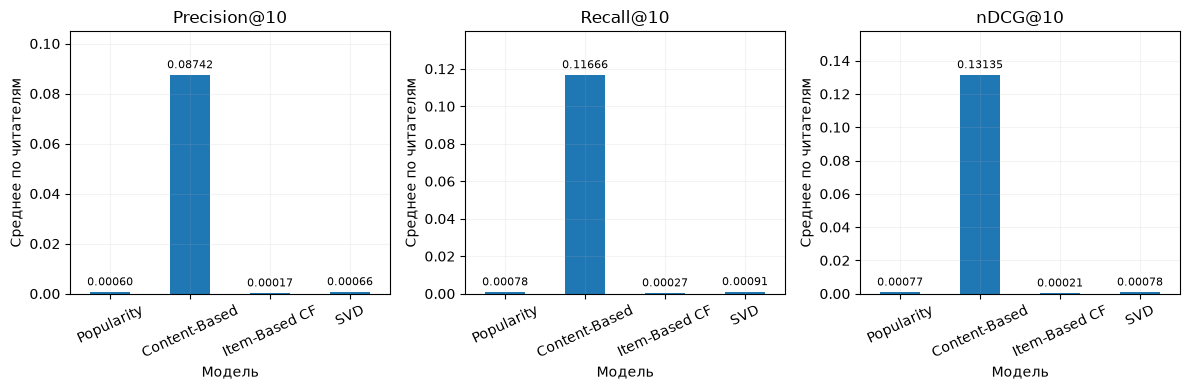

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ["Precision@10", "Recall@10", "nDCG@10"]):
    comparison[metric].plot.bar(ax=ax, rot=25)
    ax.set(title=metric, xlabel="Модель", ylabel="Среднее по читателям", ylim=(0, comparison[metric].max() * 1.2))
    ax.bar_label(ax.containers[0], fmt="%.5f", padding=3, fontsize=8)
plot_save("model_comparison")

In [23]:
examples = pd.concat([get_recommendations(1, method=name).assign(Модель=name) for name in comparison.index])
print(examples[["Модель", "book_id", "title"]].to_string(index=False))
examples.to_csv(RESULTS / "recommendation_examples.csv", index=False)

assert len(get_recommendations(-1)) == 5 and 258 not in set(get_similar_books(258).book_id)
assert not set(get_recommendations(1).book_id) & set(train_final.loc[train_final.user_id == 1, "book_id"])
summary = dict(n_ratings=len(ratings), n_users=U, n_books=I, density=density, top_10_percent_books_rating_share=top_share,
               test_size=len(test), best_svd_parameters=best_parameters, best_ndcg_model=comparison["nDCG@10"].idxmax())
(RESULTS / "experiment_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print("Проверки метрик, индексов, рекомендаций и резервных сценариев пройдены.")

       Модель  book_id                                                             title
   Popularity     3628                                    The Complete Calvin and Hobbes
   Popularity     7947                                                   ESV Study Bible
   Popularity     8978                                       The Revenge of the Baby-Sat
   Popularity     6590 The Authoritative Calvin and Hobbes: A Calvin and Hobbes Treasury
   Popularity     1788                      The Calvin and Hobbes Tenth Anniversary Book
Content-Based      172                                                     Anna Karenina
Content-Based     4692                                           The Cellist of Sarajevo
Content-Based      533                                                 Go Set a Watchman
Content-Based      395                                           For Whom the Bell Tolls
Content-Based     1912                                                          Euphoria
Item-Based CF     601

### Дополнительный анализ CF и SVD

Проведём анализ рекомендаций CF и SVD, чтобы понять, на чём основан выбор книг.
Для CF посчитаем оценённых соседей, для SVD проверим повторяемость выдачи и влияние личной части прогноза.

In [24]:
cf_support, test_support = [], []
neighbor_mask = (S > 0).T
for start in range(0, U, BATCH):
    rows = np.arange(start, min(start + BATCH, U))
    counts = (seen[rows] @ neighbor_mask).toarray()
    cf_support.append(np.take_along_axis(counts, all_top['Item-Based CF'][rows], axis=1).ravel())
    pairs = test_matrix[rows].tocoo()
    test_support.append(counts[pairs.row, pairs.col])

cf_support = np.concatenate(cf_support)
print('CF: медиана оценённых соседей в top-10:', np.median(cf_support))
print('CF: рекомендаций с одним соседом, %:', round((cf_support == 1).mean() * 100, 1))
print('CF: медиана соседей у тестовых оценок:', np.median(np.concatenate(test_support)))

CF: медиана оценённых соседей в top-10: 1.0
CF: рекомендаций с одним соседом, %: 67.3
CF: медиана соседей у тестовых оценок: 12.0


In [25]:
for name in ['Popularity', 'SVD']:
    counts = np.bincount(all_top[name].ravel(), minlength=I)
    print(name, 'разных книг в top-10:', np.count_nonzero(counts))
    print('Самая частая книга встречается в % списков:', round(counts.max() / U * 100, 1))

# Убираем личную часть SVD, оставляем только общий балл книги
matches = []
for start in range(0, U, BATCH):
    rows = np.arange(start, min(start + BATCH, U))
    scores = np.broadcast_to(bi, (len(rows), I)).copy()
    known = seen[rows].tocoo()
    scores[known.row, known.col] = -np.inf
    baseline_top = top_indices(scores, K)
    matches.extend((all_top['SVD'][rows, :, None] == baseline_top[:, None, :]).any(axis=2).sum(axis=1))
print('SVD: общих книг с выдачей без личной части, в среднем из 10:', round(np.mean(matches), 2))

Popularity разных книг в top-10: 21
Самая частая книга встречается в % списков: 99.8
SVD разных книг в top-10: 46
Самая частая книга встречается в % списков: 99.9


SVD: общих книг с выдачей без личной части, в среднем из 10: 8.12


CF в 67,3% рекомендаций опирается всего на одну оценённую книгу-соседа.
Если читатель поставил ей 5, новой книге тоже достанется прогноз около 5, хотя основание только одно.
У тестовых оценок медиана 12 соседей, а в рекомендациях - один.
Это помогает понять, как хороший RMSE сочетается с плохим подбором книг из всего каталога.

SVD выдала всего 46 разных книг на всех читателей. После удаления личной части в списке остаются
в среднем 8,12 из 10 книг. Значит, состав top-10 сильно зависит от общего балла книги,
а личные предпочтения меняют его мало. Порядок внутри списка при этом может отличаться.

## 9. Гибридный подход

Предложим сочетание моделей для читателей и книг без истории оценок.

Для нового читателя подойдут популярные книги и выбор нескольких любимых книг.
После этого можно собрать контентный профиль, а с накоплением оценок подключить CF и SVD.
Для новой книги контентная модель доступна сразу, если есть название и теги.
Её ограничение - зависимость от описаний и повторение уже знакомых тем.

Смешивать модели можно по местам в списках, поскольку их баллы имеют разные шкалы.
Для CF имеет смысл проверить минимум оценённых соседей, для SVD - подбор параметров по nDCG.
Другие варианты улучшения - эмбеддинги текста, сведения о читателях и списки `to_read`.
Это предложения для следующих экспериментов на validation, их эффект в работе не измерялся.

## 10. Выводы

В работе сравнила четыре модели на одинаковых данных. Лучше всего книги подобрала Content-Based:
nDCG@10 = 0,131, Precision@10 = 8,7%, Recall@10 = 11,7%. В среднем в десяти рекомендациях оказалось
0,87 книги с высокой тестовой оценкой. Всего модель нашла около 12% книг, которым читатели поставили
4 или 5 в тесте. На этих данных названия и теги помогли учесть интересы читателей лучше остальных подходов.

Оценки точнее всего предсказывает CF: RMSE = 0,814. У SVD ошибка 0,848, у Popularity - 0,954.
При этом по подбору книг CF оказалась последней. Эти результаты показывают, почему важно отдельно
оценивать предсказание рейтинга и сами рекомендации. При расчёте RMSE проверяем прогнозы для книг,
которые читатель оценил в тесте. При подборе модель просматривает весь каталог и выбирает десять книг
с самыми высокими прогнозами. Ошибки в этих десяти прогнозах особенно сильно влияют на результат.

Дополнительная проверка помогла разобраться с CF. В 67,3% рекомендаций модель использует оценку
только одной похожей книги. Если читатель поставил ей 5, рекомендованная книга тоже получает прогноз
около 5. Так книга может попасть в начало списка всего по одной оценке.
Для книг из теста похожих оценённых книг обычно больше: медиана 12, в рекомендациях - одна.
Получается, при подборе CF часто выбирает книги, для которых у неё слишком мало данных.
Это помогает понять разницу между хорошим RMSE и низкими метриками рекомендаций.

У SVD списки для разных читателей оказались очень похожими. На 53 424 читателей модель предложила
всего 46 разных книг. Самая частая книга встречается в 99,9% списков. Когда из прогноза убрали
личные предпочтения и оставили только общий балл книги, в списке сохранились в среднем 8,12 книги из десяти.
Значит, общий балл книги сильно влияет на то, попадёт ли она в рекомендации.
Личные предпочтения меняют состав списка сравнительно мало, хотя порядок книг внутри него может отличаться.

Ещё один интересный результат - охват каталога. У CF в рекомендации попало 99,35% книг,
у Content-Based - 79,86%, у SVD - 0,46%, у Popularity - 0,21%.
CF показала читателям почти весь каталог, но совпадений с высокими тестовыми оценками у неё меньше всего.
Content-Based тоже использовала большую часть каталога и при этом чаще находила подходящие книги.
Поэтому охват имеет смысл смотреть вместе с качеством рекомендаций.
Эта цифра показывает, сколько разных книг увидели все читатели вместе. Разнообразие десяти книг
в списке отдельного читателя - отдельный вопрос.

Popularity выбирает книги по среднему рейтингу и требует хотя бы 50 оценок.
Высокий рейтинг показывает, что книга понравилась тем, кто её оценил.
Однако у разных читателей разные интересы, а эта модель предлагает всем один список.
В нашем эксперименте такой подход редко совпадал с личными предпочтениями из теста.

В данных много пробелов: заполнено всего 1,12% матрицы. У каждого читателя оценена лишь небольшая
часть книг из каталога. При этом 10% книг получили 53,2% всех оценок, а почти 69% оценок - это 4 и 5.
Поэтому при чтении метрик важно помнить, какие предпочтения нам известны.
Precision@10 = 8,7% показывает совпадение с высокими тестовыми оценками.
Остальные рекомендованные книги читатель мог ещё не оценивать, и его отношение к ним нам неизвестно.

В этом прототипе Content-Based дала лучший результат подбора книг. Проверка CF показала, что модель часто рекомендует книгу
на основании одной высокой оценки похожей книги.
Проверка SVD показала, насколько похожими могут оставаться рекомендации при наличии личных факторов.
Эти выводы относятся к нашим настройкам и случайному разбиению данных. В датасете у всех читателей
уже есть история оценок, а даты действий отсутствуют. Работа показывает, как модели восстанавливают
скрытые оценки существующих читателей. Качество для новых читателей и будущих действий осталось за пределами этой проверки.